In [3]:
!pip install pyod

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.4/59.4 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 417.4/417.4 kB 17.6 MB/s eta 0:00:00


3.1 Ex. 1
Use the generate data() function from pyod.utils.data to generate a 2-
dimensional dataset with 500 normal samples (400 training samples and 100
test samples) with a contamination rate of 0.1.
Use pyplot.scatter() function to plot the training samples, choosing a different color for the outliers.

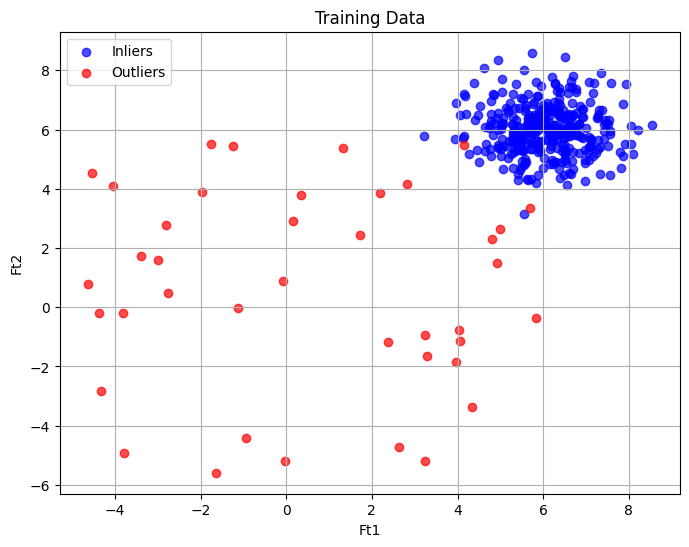

In [18]:
import matplotlib.pyplot as plt
from pyod.utils.data import generate_data

X_train, X_test, y_train, y_test = generate_data(
    n_train=400,
    n_test=100,
    n_features=2,
    contamination=0.1,
    random_state=42
)

X_train_normal = X_train[y_train == 0]
X_train_outliers = X_train[y_train == 1]

plt.figure(figsize=(8, 6))
plt.scatter(X_train_normal[:, 0], X_train_normal[:, 1], c='blue', label='Inliers', alpha=0.7)
plt.scatter(X_train_outliers[:, 0], X_train_outliers[:, 1], c='red', label='Outliers', alpha=0.7)

plt.title('Training Data')
plt.xlabel('Ft1')
plt.ylabel('Ft2')
plt.legend()
plt.grid(True)
plt.show()

3.2 Ex. 2
Choose a model from pyod (ex: KNN), leave all the parameters default (except the contamination, which will match the contamination used for dataset
generation) and fit it with the training data. Get the predictions of the model
for both the training and the testing data.
Use the confusion matrix function from sklearn.metrics to find the
number of TN, TP, FN and FP and compute the balanced accuracy.
Use the roc curve() function from sklearn.metrics to compute the ROC
curve and then plot it with plot() function.
Change the contamination rate used by the model and see how the reported
metrics change.

Train:  [[358   2]
 [  2  38]]
TN: 358, FP: 2, FN: 2, TP: 38 | Acc: 0.9722222222222222
Test: [[90  0]
 [ 1  9]]
TN: 90, FP: 0, FN: 1, TP: 9 | Acc: 0.95


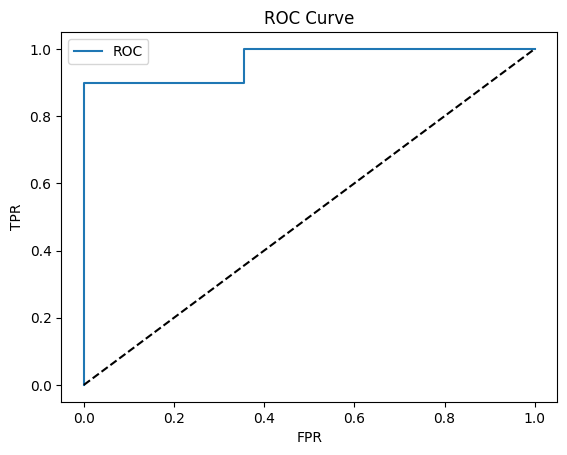

Contamination 0.03:
[[90  0]
 [ 6  4]]
TN: 90, FP: 0, FN: 6, TP: 4 | Bal Acc: 0.7000

Contamination 0.05:
[[90  0]
 [ 5  5]]
TN: 90, FP: 0, FN: 5, TP: 5 | Bal Acc: 0.7500

Contamination 0.12:
[[89  1]
 [ 1  9]]
TN: 89, FP: 1, FN: 1, TP: 9 | Bal Acc: 0.9444



In [19]:
from pyod.models.knn import KNN
from sklearn.metrics import confusion_matrix, roc_curve, balanced_accuracy_score

clf = KNN(contamination=0.1)
clf.fit(X_train)

y_train_pred = clf.labels_
y_test_pred = clf.predict(X_test)
y_test_scores = clf.decision_function(X_test)

cm_tr = confusion_matrix(y_train, y_train_pred)
cm_te = confusion_matrix(y_test, y_test_pred)

(tn_tr, fp_tr), (fn_tr, tp_tr) = cm_tr
(tn_te, fp_te), (fn_te, tp_te) = cm_te

print("Train: ", cm_tr)
print(f"TN: {tn_tr}, FP: {fp_tr}, FN: {fn_tr}, TP: {tp_tr} | Acc: {balanced_accuracy_score(y_train, y_train_pred)}")

print("Test:", cm_te)
print(f"TN: {tn_te}, FP: {fp_te}, FN: {fn_te}, TP: {tp_te} | Acc: {balanced_accuracy_score(y_test, y_test_pred)}")

fpr, tpr, _ = roc_curve(y_test, y_test_scores)
plt.plot(fpr, tpr, label='ROC')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.title('ROC Curve')
plt.legend()
plt.show()

for c in [0.03,0.05 ,0.12]:
    clf_alt = KNN(contamination=c).fit(X_train)
    y_pred = clf_alt.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)
    (tn, fp), (fn, tp) = cm

    print(f"Contamination {c}:")
    print(cm)
    print(f"TN: {tn}, FP: {fp}, FN: {fn}, TP: {tp} | Bal Acc: {balanced_accuracy_score(y_test, y_pred):.4f}\n")

3.3 Ex. 3
Generate a unidimensional dataset with 10 % contamination rate, 1000 training samples and no testing samples using generate data(). Try to detect the
anomalies in the dataset by using the Z-scores. In order to do that you should
compute the Z-score threshold that would classify the given percent (contamination rate) of data as anomalies (use np.quantile() function). Compute the
balanced accuracy of the designed method.

In [20]:
import numpy as np

X_train, _, y_train, _ = generate_data(
    n_train=1000, n_test=0, n_features=1, contamination=0.1, random_state=42
)
X_train = X_train.ravel()

mean = np.mean(X_train, axis=0)
std = np.std(X_train, axis=0)
z_scores = np.abs((X_train - mean) / std)

threshold = np.quantile(z_scores, 0.90)

y_pred = (z_scores > threshold).astype(int)

bal_acc = balanced_accuracy_score(y_train, y_pred)

print(f"Threshold: {threshold}")
print(f"Bal Acc: {bal_acc}")


Threshold: 0.9297742034791007
Bal Acc: 0.8388888888888888


3.4 Ex. 4
Same as Ex. 3 but for a multidimensional dataset. Choose your own mean
vector µ and covariance matrix Σ and build your dataset by hand starting with
the samples generated from a multivariate standard normal distribution, x ∼
N (0, I). Using the Cholesky decomposition of the covariance matrix Σ = LLT
draw your samples y like this: y = Lx + µ and then compute the Z-scores. All
other tasks as in Ex. 3.

In [23]:
n_samples = 750
n_features = 3
contamination = 0.1
np.random.seed(42)

mu = np.array([2.3, -1.1, 5.2])
Sigma = np.array([
    [1.9, 0.7, 0.4],
    [0.7, 1.4, 0.6],
    [0.4, 0.6, 1.0]
])


n_outliers = int(n_samples * contamination)
n_inliers = n_samples - n_outliers

x_inliers = np.random.randn(n_inliers, n_features)

x_outliers = np.random.uniform(low=-6, high=6, size=(n_outliers, n_features))

x = np.vstack([x_inliers, x_outliers])
y_train = np.array([0] * n_inliers + [1] * n_outliers)

L = np.linalg.cholesky(Sigma)
X_train = x @ L.T + mu

sample_mean = np.mean(X_train, axis=0)
sample_std = np.std(X_train, axis=0)
feature_z_scores = (X_train - sample_mean) / sample_std
z_scores = np.sqrt(np.sum(feature_z_scores**2, axis=1))

threshold = np.quantile(z_scores, 1.0 - contamination)
y_pred = (z_scores > threshold).astype(int)

bal_acc = balanced_accuracy_score(y_train, y_pred)

print(f"Threshold: {threshold}")
print(f"Bal Acc: {bal_acc}")


Threshold: 2.358615091273881
Bal Acc: 0.9259259259259259
